# Project Heimdall: show me the model
Team Hyperion · Hackpire Lumina 2026

This notebook loads Heimdall's **trained forecast model** and runs it live:
1. What the model is
2. One of its decision trees, in plain words
3. A live day-ahead forecast for a day it never saw
4. Accuracy over nine unseen months
5. What it relies on
6. Watching it learn, tree by tree

Run all cells (Runtime › Run all in Colab). It takes under a minute.

In [1]:
# Setup: works locally (inside the repo) or in Google Colab
import os, sys, json
if 'google.colab' in sys.modules and not os.path.exists('project-heimdall'):
    !git clone -q https://github.com/HizqeelAisy/project-heimdall
    os.chdir('project-heimdall')
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, 'pipeline')

import numpy as np, pandas as pd, lightgbm as lgb, matplotlib.pyplot as plt
from features import make_features, feature_columns
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## 1. What the model is
A LightGBM gradient-boosted model, saved as a plain text file in `models/`. It forecasts each hour's electricity load 24 hours ahead.

In [2]:
model = lgb.Booster(model_file='models/model_h24_p50.txt')
scale = pd.Series(json.load(open('models/scale.json')))   # each building's 2016 average load (kW)
print(f"Trees in the model : {model.num_trees():,}")
print(f"Inputs it uses     : {len(model.feature_name())}")
print(f"Objective          : {model.params.get('objective')} (median forecast)")
print(f"File size          : {os.path.getsize('models/model_h24_p50.txt')/1e6:.1f} MB")
print("Inputs:", ", ".join(model.feature_name()))

Trees in the model : 1,889
Inputs it uses     : 21
Objective          : quantile (median forecast)
File size          : 11.8 MB
Inputs: hour, dow, weekend, month, holiday, temp, dew, temp_roll24, temp_max_today, cdd, roll24_mean, roll24_max, roll168_mean, building_cat, site_cat, lag_24, lag_25, lag_26, lag_48, lag_168, lag_336


## 2. One decision tree, in plain words
Each tree is a short chain of yes/no questions that ends in a small adjustment. Here is the first tree, top three levels. Load is measured relative to the building's normal level (1.00 = average).

In [3]:
NAMES = {'lag_168': 'load at this hour last week', 'lag_24': 'load at this hour yesterday', 'lag_25': 'load yesterday, 1h earlier',
         'lag_26': 'load yesterday, 2h earlier', 'lag_48': 'load 2 days ago', 'lag_336': 'load at this hour 2 weeks ago',
         'hour': 'hour of day', 'dow': 'day of week (0=Mon)', 'temp': 'temperature (°C)', 'roll24_mean': 'average load, last known 24h'}
tree = model.dump_model()['tree_info'][0]['tree_structure']
feats = model.feature_name()
def show(node, depth=0, max_depth=3):
    pad = '    ' * depth
    if 'split_feature' in node:
        f = feats[node['split_feature']]; t = node['threshold']
        t = f'{t:.2f}' if isinstance(t, float) else t
        if depth >= max_depth:
            print(pad + '…'); return
        print(f"{pad}Is {NAMES.get(f, f)} ≤ {t}?")
        print(pad + '  yes →'); show(node['left_child'], depth + 1, max_depth)
        print(pad + '  no  →'); show(node['right_child'], depth + 1, max_depth)
    else:
        print(f"{pad}adjust forecast by {node['leaf_value']:+.3f}")
show(tree)

Is load at this hour last week ≤ 0.98?
  yes →
    Is load yesterday, 1h earlier ≤ 0.98?
      yes →
        Is load at this hour 2 weeks ago ≤ 0.97?
          yes →
            …
          no  →
            …
      no  →
        Is load at this hour 2 weeks ago ≤ 0.98?
          yes →
            …
          no  →
            …
  no  →
    Is load yesterday, 1h earlier ≤ 0.99?
      yes →
        Is day of week (0=Mon) ≤ 0.00?
          yes →
            …
          no  →
            …
      no  →
        Is load at this hour 2 weeks ago ≤ 1.01?
          yes →
            …
          no  →
            …


## 3. A live forecast for a day the model never saw
Change `BUILDING` and `DAY` to try others. The model only sees information available the day before.

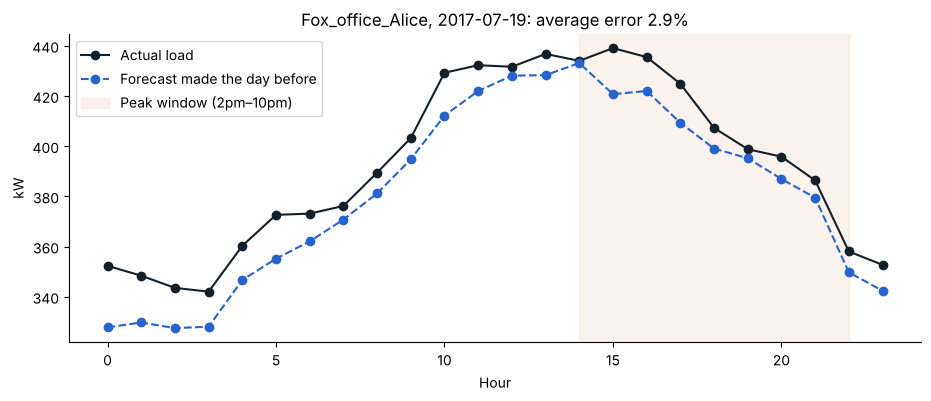

In [4]:
BUILDING = 'Fox_office_Alice'      # try: Bull_office_Lilla, Fox_education_Wendell, Bull_public_Hyun
DAY = '2017-07-19'                  # any day from 2017-04-01 to 2017-12-31 (test period)

data = pd.read_csv('pipeline/sample/demo_buildings.csv.gz', parse_dates=['timestamp'])
feat = make_features(data, horizon=24, scale=scale)
cols = feature_columns(feat)
day = feat[(feat.building == BUILDING) & (feat.timestamp.dt.strftime('%Y-%m-%d') == DAY)].copy()
day['forecast_kw'] = model.predict(day[cols]) * scale[BUILDING]

err = (abs(day.kw - day.forecast_kw) / day.kw).mean() * 100
ax = plt.gca()
ax.plot(day.timestamp.dt.hour, day.kw, 'o-', color='#132029', label='Actual load')
ax.plot(day.timestamp.dt.hour, day.forecast_kw, 'o--', color='#2463D1', label='Forecast made the day before')
ax.axvspan(14, 22, color='#C9711A', alpha=0.08, label='Peak window (2pm–10pm)')
ax.set(xlabel='Hour', ylabel='kW', title=f'{BUILDING}, {DAY}: average error {err:.1f}%'); ax.legend(); plt.show()

### Why it forecast 3pm the way it did
Follow one hour through the first tree, question by question, to the adjustment it lands on. The final forecast adds up all 1,889 of these adjustments.

In [5]:
row = day[day.timestamp.dt.hour == 15].iloc[0]
node, step = tree, 1
while 'split_feature' in node:
    f = feats[node['split_feature']]; t = node['threshold']; v = row[f]
    if isinstance(t, float):
        go_left = v <= t
        print(f"{step}. Is {NAMES.get(f, f)} ≤ {t:.2f}?  It is {v:.2f} → {'yes' if go_left else 'no'}")
    else:
        go_left = str(row['building_cat'] if f == 'building_cat' else v) in t.split('||')
        print(f"{step}. Is this one of a group of {f.replace('_cat','')}s?  → {'yes' if go_left else 'no'}")
    node = node['left_child'] if go_left else node['right_child']; step += 1
print(f"→ Tree 1 lands on {node['leaf_value']:.3f} × normal load. (The first tree carries the starting average;")
print("   every later tree adds a small correction on top.)")
print(f"After all {model.num_trees():,} trees: {row.forecast_kw:.0f} kW forecast vs {row.kw:.0f} kW actual")

1. Is load at this hour last week ≤ 0.98?  It is 1.13 → no
2. Is load yesterday, 1h earlier ≤ 0.99?  It is 1.21 → no
3. Is load at this hour 2 weeks ago ≤ 1.01?  It is 1.17 → no
4. Is holiday ≤ 0.00?  It is 0.00 → yes
5. Is load at this hour last week ≤ 1.04?  It is 1.13 → no
6. Is load yesterday, 1h earlier ≤ 1.05?  It is 1.21 → no
→ Tree 1 lands on 0.995 × normal load. (The first tree carries the starting average;
   every later tree adds a small correction on top.)
After all 1,889 trees: 421 kW forecast vs 439 kW actual


## 4. Accuracy over nine unseen months (April to December 2017)
Compared with the obvious shortcut: "same hour last week".

In [6]:
test = feat[feat.timestamp > '2017-03-31 23:00'].dropna(subset=['kw'] + [c for c in cols if c.startswith('lag_')]).copy()
test['forecast_kw'] = model.predict(test[cols]) * test.building.map(scale)
test['naive_kw'] = test.lag_168 * test.building.map(scale)
mape = lambda f: (abs(test.kw - test[f]) / test.kw).groupby(test.building).mean() * 100
table = pd.DataFrame({'Heimdall error %': mape('forecast_kw'), 'Last-week shortcut error %': mape('naive_kw')}).round(2)
table.loc['Average'] = table.mean().round(2)
table

,Heimdall error %,Last-week shortcut error %
building,,
Bull_education_Arthur,3.99,5.35
Bull_office_Lilla,2.71,4.46
Bull_public_Hyun,2.81,4.17
Fox_assembly_Johnnie,9.60,11.85
Fox_education_Wendell,1.53,2.46
Fox_office_Alice,2.24,3.34
Average,3.81,5.27


## 5. What the model relies on

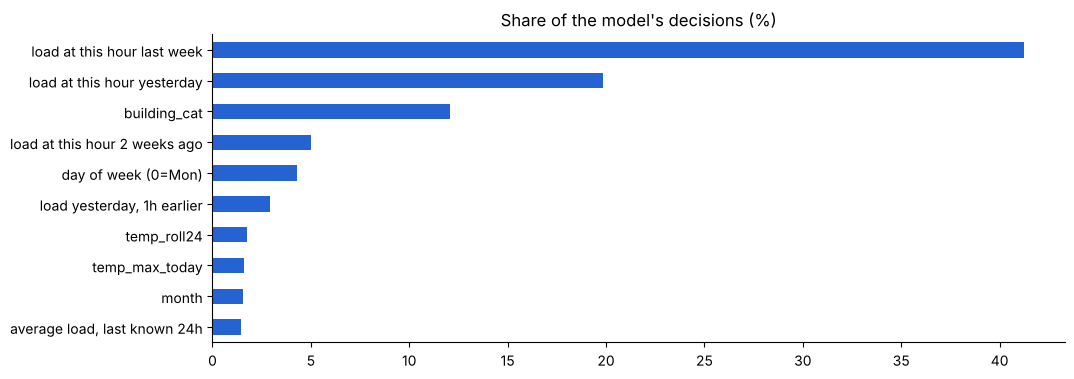

In [7]:
imp = pd.Series(model.feature_importance('gain'), index=feats)
imp = (imp / imp.sum() * 100).sort_values().tail(10)
imp.index = [NAMES.get(i, i) for i in imp.index]
imp.plot.barh(color='#2463D1', title='Share of the model\'s decisions (%)'); plt.show()

## 6. Watching it learn, tree by tree
Gradient boosting adds small trees one at a time; each corrects what the earlier ones still get wrong.

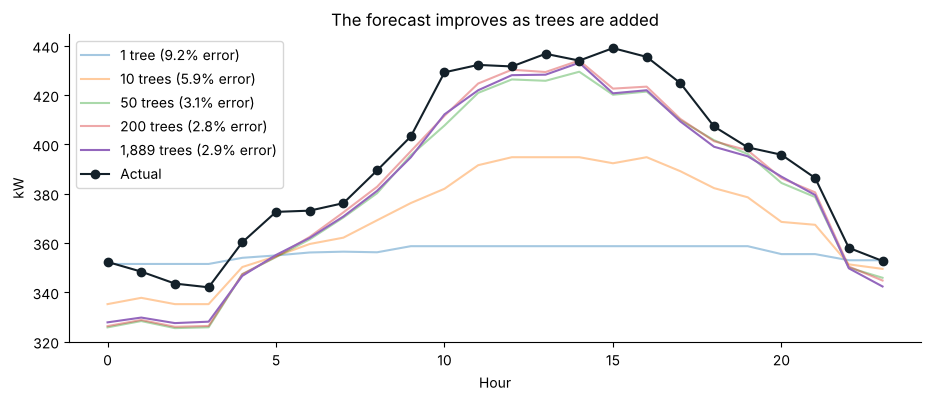

In [8]:
for n in [1, 10, 50, 200, model.num_trees()]:
    pred = model.predict(day[cols], num_iteration=n) * scale[BUILDING]
    e = (abs(day.kw - pred) / day.kw).mean() * 100
    plt.plot(day.timestamp.dt.hour, pred, label=f"{n:,} tree{'s' if n > 1 else ''} ({e:.1f}% error)", alpha=0.4 + 0.6 * (n == model.num_trees()))
plt.plot(day.timestamp.dt.hour, day.kw, 'o-', color='#132029', label='Actual')
plt.xlabel('Hour'); plt.ylabel('kW'); plt.legend(); plt.title('The forecast improves as trees are added'); plt.show()